# Repertoire similarity and structural cost

**Question:** Do ensemble sequences score more like human antibodies, and what happens to predicted structure?

**Reader:** outputs below are from the included real public results, not synthetic demonstrations. [Compact GitHub reader](READ_RESULTS.md). **Student:** run each step, inspect the rows, then explain the result in your own words. You will choose files → inspect → validate → calculate → plot → interpret → optionally export. Nothing is scored or folded here. [Student guide and schemas](README.md).

## 1 · Choose local inputs

First run: leave these paths alone. For your own compatible results, copy files into `inputs/my_run/` using Finder/Explorer or a **local** JupyterLab file browser Upload button. In VS Code use the local folder explorer. Do not use a remote notebook server or cloud upload. This code never transmits files.

Edit a copy of `selection.csv`: one workbook and matching FASTA for each case/method. Paths inside that CSV are relative to this notebook folder, **not** to the CSV location. Select structural and ablation CSVs below too. Set `ABLATION = None` to omit the separate ablation; the main analysis requires all measured loops. Only the two supported cases and existing endpoint conventions are supported. A new metric needs a mentor-reviewed design, not relabelled columns.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import analysis
from workflow import read_inputs, validate_inputs, status, export_bundle
ROOT = Path.cwd()  # Open this notebook in its package folder.
SELECTION = 'selection.csv'
STRUCTURAL = 'inputs/cdr_rmsd_results.csv'
ABLATION = 'inputs/ablation_scores.csv'  # or None; never silently substituted

## 2 · What did we actually select?

Run this cell to read the files, not compute results. Check the paths, antibody IDs, units and first rows. BioPhi’s heavy-domain Identity is a fraction from 0 to 1, including for scFv. The structural table has one row per design **and loop**. The original file also contains AbMPNN; the comparison explicitly excludes that arm. Do these files describe the same main designs?

In [2]:
data = None  # invalidate the previous in-memory analysis before a new read
loaded = None
loaded = read_inputs(ROOT, SELECTION, STRUCTURAL, ABLATION)
display(loaded['selection'])
for key, sheets in loaded['books'].items():
    print(key, 'Overview — first 3 actual rows')
    display(sheets['Overview'][['Antibody', 'Heavy OASis Identity']].head(3))
display(loaded['structural'].head(5))
if loaded['ablation'] is not None:
    display(loaded['ablation'].head(4))

,structure,method,workbook,fasta
0,9NH7,baseline,inputs/9NH7_baseline.xlsx,inputs/9NH7_baseline.fa
1,9NH7,ensemble,inputs/9NH7_ensemble.xlsx,inputs/9NH7_ensemble.fa
2,9NFU,baseline,inputs/9NFU_baseline.xlsx,inputs/9NFU_baseline.fa
3,9NFU,ensemble,inputs/9NFU_ensemble.xlsx,inputs/9NFU_ensemble.fa


('9NH7', 'baseline') Overview — first 3 actual rows


,Antibody,Heavy OASis Identity
0,9NH7_ProteinMPNN_sample1,0.607477
1,9NH7_ProteinMPNN_sample10,0.616822
2,9NH7_ProteinMPNN_sample100,0.570093


('9NH7', 'ensemble') Overview — first 3 actual rows


,Antibody,Heavy OASis Identity
0,9NH7_seed000,0.841121
1,9NH7_seed001,0.841121
2,9NH7_seed002,0.831776


('9NFU', 'baseline') Overview — first 3 actual rows


,Antibody,Heavy OASis Identity
0,9NFU_ProteinMPNN_sample1,0.646018
1,9NFU_ProteinMPNN_sample10,0.646018
2,9NFU_ProteinMPNN_sample100,0.654867


('9NFU', 'ensemble') Overview — first 3 actual rows


,Antibody,Heavy OASis Identity
0,9NFU_seed000,0.911504
1,9NFU_seed001,0.867257
2,9NFU_seed002,0.831858


,structure,method,design_id,cdr,domain,rmsd_angstrom,n_residues,n_atoms_per_residue,cdr_mean_plddt,low_confidence,framework_rmsd_angstrom,framework_outlier
0,9NH7,baseline,9NH7_baseline_000,H1,VHH,2.549,8,3,82.17,0,1.462,0
1,9NH7,baseline,9NH7_baseline_000,H2,VHH,0.770,8,3,88.58,0,1.462,0
2,9NH7,baseline,9NH7_baseline_000,H3,VHH,0.958,15,3,86.29,0,1.462,0
3,9NH7,baseline,9NH7_baseline_001,H1,VHH,2.635,8,3,81.33,0,1.454,0
4,9NH7,baseline,9NH7_baseline_001,H2,VHH,0.864,8,3,86.08,0,1.454,0


,id,oasis,Heavy OASis Identity,Light OASis Identity
0,9NFU_cdrh3_baseline_s0,0.665072,0.654867,0.677083
1,9NFU_cdrh3_baseline_s1,0.665072,0.654867,0.677083
2,9NFU_cdrh3_baseline_s10,0.665072,0.654867,0.677083
3,9NFU_cdrh3_baseline_s11,0.665072,0.654867,0.677083


## 3 · Do the identities and measurements pass the checks?

Checks require scored VH → indexed FASTA correspondence, unique structural keys, complete loops, supported domains/three backbone atoms, finite score/RMSD/pLDDT ranges and correct confidence flags. Ablation pairs join by **reported seed**, never row order. Counts may differ between main arms; no minimum of 100 is imposed.

**If a check fails:** stop; read the named file/row/key, correct the source export or selected path, then restart and run from step 1. Do not delete difficult rows, fill missing measurements, or use old visible plots. Clear notebook outputs after a failed interactive run. Previously exported folders are historical and stay untouched. Passing these checks is computational compatibility, not certification of the experimental protocol.

In [3]:
data = None
data = validate_inputs(loaded)
display(Markdown(status(data)))
display(data['main'].groupby(['structure','method']).agg(
    draws=('index','size'), heavy_median=('oasis','median'),
    H3_below70=('low_confidence','sum')))
print('Scored VH/FASTA and complete-loop checks passed. Main arms remain unpaired.')

Pinned retained-input analysis. For the pinned original inputs, prior audit linked scored VH to final-filled FASTAs and full predicted sequences, and replayed the implemented coordinate measurements without numeric discrepancies. This package rechecks the scored-VH/FASTA link and recalculates retained metrics; it does not rerun coordinate replay, folding or BioPhi scoring. Computation verification is distinct from independent biological mapping or causal acceptance.

draws  heavy_median  H3_below70
structure method                                   
9NFU      baseline    100      0.654867           0
          ensemble    100      0.858407          18
9NH7      baseline    100      0.598131           0
          ensemble    100      0.813084          32

Scored VH/FASTA and complete-loop checks passed. Main arms remain unpaired.


## 4 · Predict, then calculate

**Before running:** predict which arm has the higher heavy-domain score in each case. Does a higher similarity score force lower RMSD?

The code first groups actual observations to show medians and counts. A delta is **ensemble median − baseline median**, not the median of paired differences. All draws (including repeated sequences and low-confidence predictions) keep their weight. These are descriptive summaries, not confidence intervals or significance tests.

In [4]:
main = data['main']
grouped = main.groupby(['structure','method'])[['oasis','rmsd_angstrom']].median()
display(grouped.rename(columns={'oasis':'Heavy Identity median','rmsd_angstrom':'H3 median (Å)'}))
deltas = grouped.xs('ensemble',level='method') - grouped.xs('baseline',level='method')
display(deltas.rename(columns={'oasis':'Δ marginal Identity median','rmsd_angstrom':'Δ marginal H3 median (Å)'}))
table, ablation_table = analysis.summarize(data)  # same formulas + separate domain denominators
assert table.set_index('structure').biophi_heavy_difference_medians.sort_index().equals(deltas.oasis.sort_index())
loops, loop_readout = analysis.loop_summary(data)
display(analysis.table_display(table))

Heavy Identity median  H3 median (Å)
structure method                                        
9NFU      baseline               0.654867         2.9390
          ensemble               0.858407         3.0595
9NH7      baseline               0.598131         0.8960
          ensemble               0.813084         2.2750

,Δ marginal Identity median,Δ marginal H3 median (Å)
structure,,
9NFU,0.203540,0.1205
9NH7,0.214953,1.3790


,Case,"Heavy-domain Identity, B → E",Δ Identity,"H3 RMSD, B → E (Å)",Δ RMSD (Å)
0,9NH7,0.5981 → 0.8131,+0.2150,0.8960 → 2.2750,+1.3790
1,9NFU,0.6549 → 0.8584,+0.2035,2.9390 → 3.0595,+0.1205


## 5 · Four views of the main comparison

Each panel is drawn from the loaded frames, not a PNG. Colors and scales agree across cases. Structural dots are medians; lines show the middle 50%, not confidence intervals. Main arms remain unpaired. The optional export also creates a compact 2×2 manuscript figure: cases in columns, metrics in rows.

### 9NH7 · Does ensemble increase heavy-domain repertoire similarity?

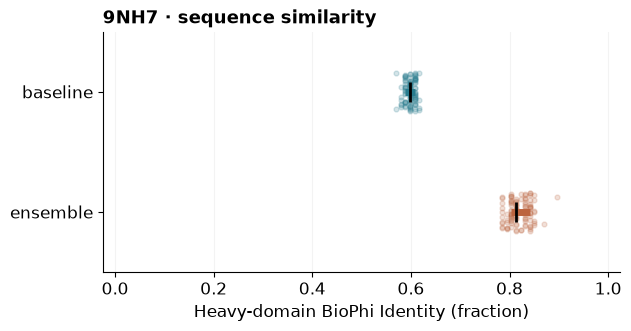

In [5]:
panel_9NH7_similarity = analysis.plot_panel(data, '9NH7', 'similarity')
display(panel_9NH7_similarity)
plt.close(panel_9NH7_similarity)

In [6]:
display(Markdown(analysis.panel_readout(data, '9NH7', 'similarity')))

9NH7: baseline n=100, ensemble n=100. Heavy-domain Identity medians: 0.5981 → 0.8131; ensemble is higher (Δ +0.2150). Light dots are all draws; black ticks are medians; thick lines are the middle 50%, not confidence intervals. This is repertoire similarity, not immune response. Reflect: does the structural panel support the same favorable direction?

### 9NH7 · What structural trade-off accompanies the similarity result?

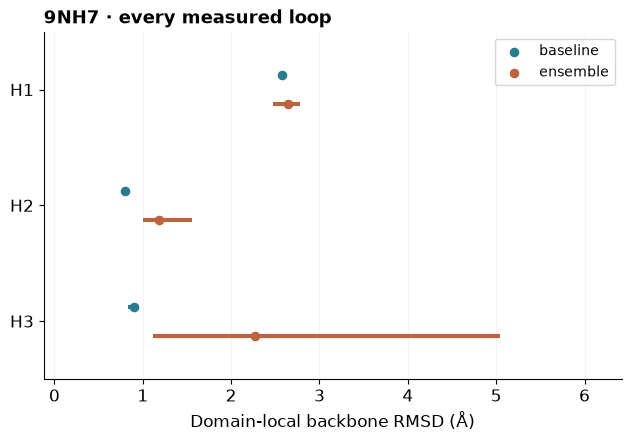

In [7]:
panel_9NH7_structure = analysis.plot_panel(data, '9NH7', 'structure')
display(panel_9NH7_structure)
plt.close(panel_9NH7_structure)

In [8]:
display(Markdown(analysis.panel_readout(data, '9NH7', 'structure')))

9NH7: baseline n=100, ensemble n=100. Loop median RMSD in Å, baseline → ensemble: H1 2.574 → 2.647 (Δ +0.074); H2 0.801 → 1.184 (Δ +0.383); H3 0.896 → 2.275 (Δ +1.379). Structural dots are medians; lines are the middle 50%, not confidence intervals. The ensemble has higher similarity and higher H3 RMSD. Reflect: is this a similarity/structure trade-off in these inputs? It is not evidence of preserved binding.

### 9NFU · Does the heavy-only similarity pattern recur in the scFv case?

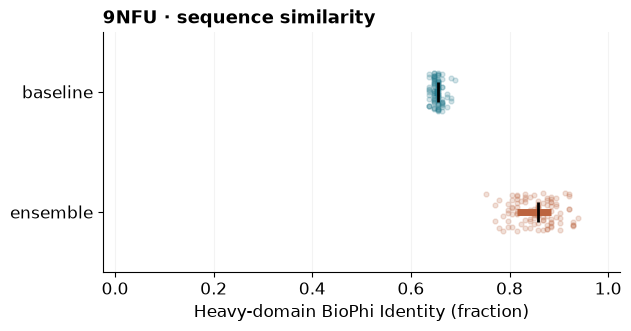

In [9]:
panel_9NFU_similarity = analysis.plot_panel(data, '9NFU', 'similarity')
display(panel_9NFU_similarity)
plt.close(panel_9NFU_similarity)

In [10]:
display(Markdown(analysis.panel_readout(data, '9NFU', 'similarity')))

9NFU: baseline n=100, ensemble n=100. Heavy-domain Identity medians: 0.6549 → 0.8584; ensemble is higher (Δ +0.2035). Light dots are all draws; black ticks are medians; thick lines are the middle 50%, not confidence intervals. This is repertoire similarity, not immune response. The scFv score here is heavy-only, not a pooled VH/VL endpoint. Reflect: does the structural panel support the same favorable direction?

### 9NFU · What does H3 miss about the other heavy and light loops?

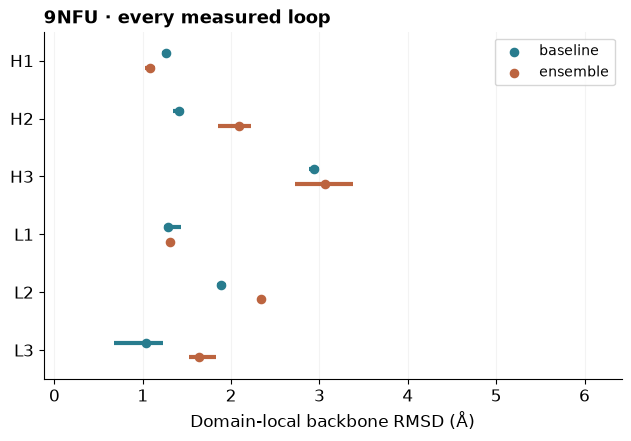

In [11]:
panel_9NFU_structure = analysis.plot_panel(data, '9NFU', 'structure')
display(panel_9NFU_structure)
plt.close(panel_9NFU_structure)

In [12]:
display(Markdown(analysis.panel_readout(data, '9NFU', 'structure')))

9NFU: baseline n=100, ensemble n=100. Loop median RMSD in Å, baseline → ensemble: H1 1.266 → 1.083 (Δ -0.183); H2 1.407 → 2.087 (Δ +0.679); H3 2.939 → 3.059 (Δ +0.120); L1 1.286 → 1.307 (Δ +0.020); L2 1.882 → 2.333 (Δ +0.452); L3 1.032 → 1.639 (Δ +0.607). Structural dots are medians; lines are the middle 50%, not confidence intervals. Across 9NFU loops, median RMSD increases larger than its H3 shift occur in H2, L2, L3; decreases (improvements relative to the reference) occur in H1. The H3 result is not overall scFv preservation. The complete supporting loop table retains all draws. Low confidence means mean loop pLDDT below 70, not any low-confidence residue, and does not explain away every worsening: 9NFU H2 below-70 counts are 0 baseline and 0 ensemble. Reflect: which other loops change the conclusion you would draw from H3 alone?

In [13]:
readout, case_details, region_readout = analysis.describe(data, table, ablation_table)

### Check your prediction

Write two sentences: (1) a numerical observation for one case, (2) a limitation that changes its interpretation. Compare H3 with the other loops before calling a structural cost small.

**Worked example for the included dataset only:** “The 9NH7 ensemble heavy-domain median is higher, but its H3 median RMSD is also higher. This is a similarity/structure trade-off in retained predictions, not evidence of preserved binding.” Verify both directions against your current table; do **not** reuse this sentence if your values differ.

**Hypothesis:** a protocol difference might contribute to the score shift; these summaries do not identify the cause. **Unestablished claims:** reduced immunogenicity, preserved binding, structural non-inferiority, a general antibody-format effect, or AbLang-only causation.

## 6 · Supporting evidence: spread and confidence

Read every loop, not only a favorable endpoint. Mean loop pLDDT < 70 flags low confidence; it does not establish why a structure changed and does not remove a draw. Domain-local fits omit relative VH/VL orientation. Mapping is operational/motif-based, not independently validated biological numbering.

,structure,cdr,baseline_n,baseline_median_A,baseline_below70,ensemble_n,ensemble_median_A,ensemble_below70
0,9NH7,H1,100,2.5735,0,100,2.6475,0
1,9NH7,H2,100,0.8010,0,100,1.1840,0
2,9NH7,H3,100,0.8960,0,100,2.2750,32
3,9NFU,H1,100,1.2660,0,100,1.0835,0
4,9NFU,H2,100,1.4070,0,100,2.0865,0
5,9NFU,H3,100,2.9390,0,100,3.0595,18
6,9NFU,L1,100,1.2865,0,100,1.3070,0
7,9NFU,L2,100,1.8820,0,100,2.3335,11
8,9NFU,L3,100,1.0320,0,100,1.6395,6


**9NH7.** H3 interquartile ranges are 0.835–0.959 Å (baseline) and 1.121–5.047 Å (ensemble); these ranges do not overlap. The ensemble middle-half spread is higher. Mean H3 RMSD is 0.90177 → 2.91623 Å; framework medians are 1.453 → 1.433 Å. H3 mean pLDDT is below 70 in 0/100 → 32/100 designs. All remain in the primary summaries; low confidence weakens interpretation as a true fold, not the retained arithmetic.

**9NFU.** H3 interquartile ranges are 2.881–2.995 Å (baseline) and 2.722–3.384 Å (ensemble); these ranges overlap. The ensemble middle-half spread is higher. Mean H3 RMSD is 2.94351 → 2.98316 Å; framework medians are 1.008 → 1.020 Å. H3 mean pLDDT is below 70 in 0/100 → 18/100 designs. All remain in the primary summaries; low confidence weakens interpretation as a true fold, not the retained arithmetic.

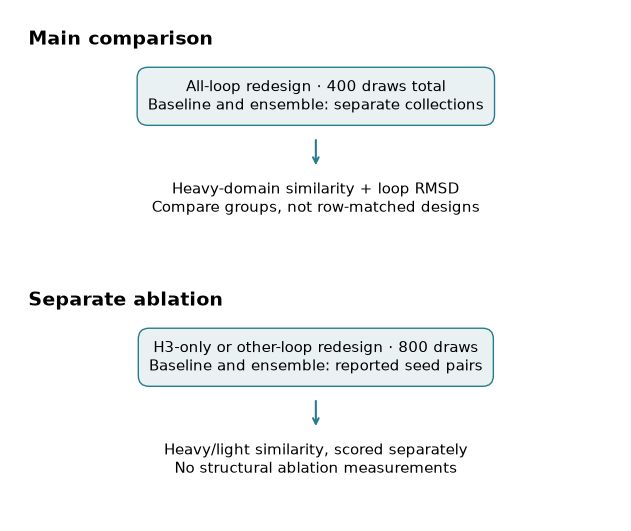

In [14]:
display(loops.round(4))
for detail in case_details:
    display(Markdown(detail))
map_figure = analysis.plot_experiment_map(data)
display(map_figure)
plt.close(map_figure)

## 7 · Separate ablation: calculate reported pair differences

This is another cohort, not a pairing of the main designs. Here the key is case + condition + reported seed. Look at the explicit join and subtraction below. `others` is H1/H2 for 9NH7, but H1/H2 **plus L1/L2/L3** for 9NFU; the latter is not an isolated heavy-loop intervention. Heavy and light endpoints are kept separate.

**Predict:** should every pair have the same sign just because the mean is positive? Check rather than assume.

In [15]:
ablation = data['ablation']
if not ablation.empty:
    pairs = ablation.pivot(index=['structure','condition','seed'], columns='method', values='Heavy OASis Identity')
    pairs['difference_pp'] = 100 * (pairs['ensemble'] - pairs['baseline'])
    display(pairs.head(6))
    display(pairs.groupby(['structure','condition']).difference_pp.agg(['size','mean','min','max']))
    display(ablation_table[['structure','condition','domain','n_pairs','mean_difference','positive','negative','zero']])
else:
    print('Ablation not selected: no pair differences or causal interpretation computed.')

method                    baseline  ensemble  difference_pp
structure condition seed                                   
9NFU      cdrh3     0     0.654867  0.707965       5.309735
                    1     0.654867  0.707965       5.309735
                    10    0.654867  0.716814       6.194690
                    11    0.654867  0.707965       5.309735
                    12    0.654867  0.725664       7.079646
                    13    0.654867  0.725664       7.079646

size       mean        min        max
structure condition                                       
9NFU      cdrh3       100   5.548673   3.539823   7.964602
          others      100   8.504425   2.654867  16.814159
9NH7      cdrh3       100   5.869159   3.738318   7.476636
          others      100  15.093458  11.214953  17.757009

,structure,condition,domain,n_pairs,mean_difference,positive,negative,zero
0,9NFU,cdrh3,H,100,0.055487,100,0,0
1,9NFU,cdrh3,L,100,0.000000,0,0,100
2,9NFU,others,H,100,0.085044,100,0,0
3,9NFU,others,L,100,0.140313,100,0,0
4,9NH7,cdrh3,H,100,0.058692,100,0,0
5,9NH7,others,H,100,0.150935,100,0,0


## 8 · Figure 2: inspect the distribution, not just its mean

Dots are reported seed-pair differences in percentage points; diamonds are means; thick lines are IQRs. A positive value favors ensemble similarity. The source-defined zero-logit control’s executed helper/weights remain unauthenticated for the original dataset; new files need their own protocol evidence. No matched structural ablation measurements are supplied.

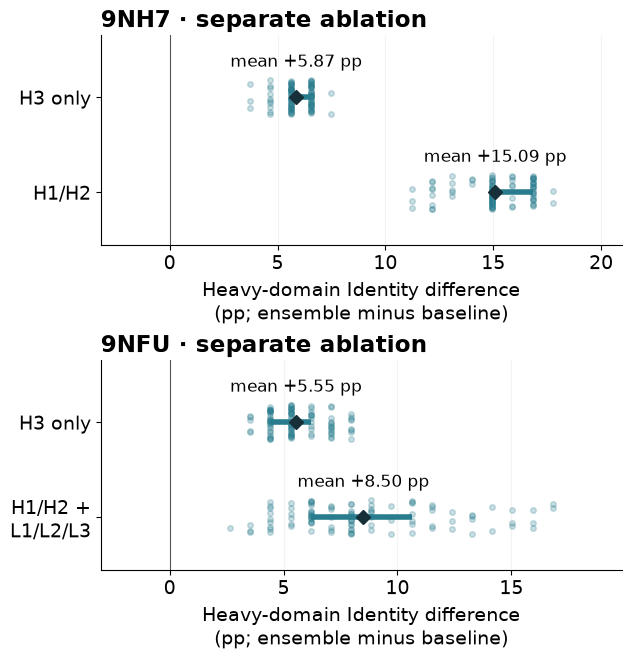

**Computed observations:** 9NH7: the mean difference outside H3 is higher than H3-only (+0.15093 versus +0.05869); positive reported pairs: 100/100 versus 100/100. 9NFU: the mean difference outside H3 is higher than H3-only (+0.08504 versus +0.05549); positive reported pairs: 100/100 versus 100/100.

In [16]:
if not ablation.empty:
    ablation_figure = analysis.plot_ablation(ablation_table, ablation)
    display(ablation_figure)
    plt.close(ablation_figure)
    display(Markdown('**Computed observations:** ' + region_readout))
else:
    ablation_figure = None
    print('Figure 2 omitted — no selected ablation.')

## 9 · Explain the result yourself

Replace the notes below before exporting. Use values from your selected tables, not an AI verdict.

- **Observation:** which case, endpoint, contrast and draw count? Name an adverse or heterogeneous result too.
- **Check:** do plotted dots/medians agree with the small tables? Are confidence counts plausible? Is any endpoint being confused with another?
- **Hypothesis:** one possible explanation and what evidence would discriminate it.
- **Limit:** what remains unestablished? What would you ask a mentor before designing a new metric or inferential test?
- **Reflection:** did your prediction hold? What changed your mind?

In [17]:
student_notes = {
    'observation': '',
    'sanity_check': '',
    'hypothesis_and_test': '',
    'limitation_and_mentor_question': '',
    'reflection': '',
}
display(Markdown(analysis.LIMIT))

Neither overlapping ranges nor a small mean shift establishes structural non-inferiority: a meaningful margin and justified uncertainty analysis are needed. Predicted RMSD does not measure binding. These are draw-weighted designs on two fixed cases, not independent biological experiments or evidence of an antibody-format effect. No p-values, confidence intervals, or causal acceptance are inferred here.

## 10 · Optional export — only when you choose

First **Restart Kernel and Run All** with export off; compare your outputs, complete your notes and save the notebook. Then set `EXPORT = True` below and run this cell. It writes tables, figures, same-source GitHub/mobile readers, exact selected input bytes, hashes and versions into a **new UTC-dated folder** under `exports/`. No old export or included example is overwritten. Keep your saved executed notebook with it. Reset the switch to `False` before the next restart. A software check is not scientific endorsement; review privacy before sharing your own inputs.

In [18]:
EXPORT = False
if EXPORT:
    if not all(value.strip() for value in student_notes.values()):
        raise ValueError('Complete the five reasoning notes before exporting; use your own words.')
    export_path = export_bundle(ROOT, data, confirm=True)
    import json
    (export_path / 'student-notes.json').write_text(json.dumps(student_notes, indent=2))
    print('New local export:', export_path.relative_to(ROOT))
else:
    print('Export is off. No analysis outputs were written.')

Export is off. No analysis outputs were written.
